# Implementation and Time Analysis of Sorting Algorithms

This notebook implements and analyzes five classic sorting algorithms:

1. Bubble Sort
2. Selection Sort
3. Insertion Sort
4. Merge Sort
5. Quick Sort

For each algorithm you will find:
- Python implementation
- User input (enter your own list of numbers)
- Runtime measurement (using `time` module)
- Time Complexity (Best, Average, Worst case)
- Space Complexity

At the end, all five algorithms are compared on the same random dataset with a runtime chart.


In [1]:
# Common imports used throughout the notebook
import time
import random
import matplotlib.pyplot as plt

def get_user_list(demo_string=None):
    """Takes a comma-separated list of numbers.

    - Interactive use: call get_user_list() with NO arguments. It will prompt
      you with input() to type your own numbers, e.g.  5,3,8,1,9
    - This notebook (pre-run with saved outputs): each demo cell below calls
      get_user_list(\"64,34,25,...\") with a sample string instead, purely so
      the notebook can be executed top-to-bottom non-interactively and still
      show real output. Remove the argument any time you want to type your
      own list instead.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter numbers separated by commas (e.g., 5,3,8,1,9): "
    )
    try:
        arr = [int(x.strip()) for x in raw.split(',') if x.strip() != '']
    except ValueError:
        print("Invalid input detected, using a default sample list instead.")
        arr = [5, 3, 8, 1, 9, 2]
    return arr


## 1. Bubble Sort

In [2]:
def bubble_sort(arr):
    a = arr.copy()
    n = len(a)
    for i in range(n - 1):
        swapped = False
        for j in range(n - 1 - i):
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swapped = True
        if not swapped:
            break
    return a


In [3]:
# --- Bubble Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("64,34,25,12,22,11,90")
print("Original list:", user_arr)

start = time.time()
sorted_arr = bubble_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [64, 34, 25, 12, 22, 11, 90]
Sorted list  : [11, 12, 22, 25, 34, 64, 90]
Runtime      : 0.048399 ms


**Time Complexity**
- Best Case: `O(n)` — when the array is already sorted (with the `swapped` flag optimization)
- Average Case: `O(n^2)`
- Worst Case: `O(n^2)` — reverse sorted array

**Space Complexity:** `O(1)` — sorts in place, only a temporary variable used for swapping.


## 2. Selection Sort

In [4]:
def selection_sort(arr):
    a = arr.copy()
    n = len(a)
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            if a[j] < a[min_idx]:
                min_idx = j
        a[i], a[min_idx] = a[min_idx], a[i]
    return a


In [5]:
# --- Selection Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("29,10,14,37,14,1,8")
print("Original list:", user_arr)

start = time.time()
sorted_arr = selection_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [29, 10, 14, 37, 14, 1, 8]
Sorted list  : [1, 8, 10, 14, 14, 29, 37]
Runtime      : 0.103951 ms


**Time Complexity**
- Best Case: `O(n^2)`
- Average Case: `O(n^2)`
- Worst Case: `O(n^2)`

(Selection sort always scans the remaining unsorted part to find the minimum, regardless of initial order, so all cases are `O(n^2)`.)

**Space Complexity:** `O(1)` — sorts in place.


## 3. Insertion Sort

In [6]:
def insertion_sort(arr):
    a = arr.copy()
    for i in range(1, len(a)):
        key = a[i]
        j = i - 1
        while j >= 0 and a[j] > key:
            a[j + 1] = a[j]
            j -= 1
        a[j + 1] = key
    return a


In [7]:
# --- Insertion Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("12,11,13,5,6")
print("Original list:", user_arr)

start = time.time()
sorted_arr = insertion_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [12, 11, 13, 5, 6]
Sorted list  : [5, 6, 11, 12, 13]
Runtime      : 0.054836 ms


**Time Complexity**
- Best Case: `O(n)` — already sorted array
- Average Case: `O(n^2)`
- Worst Case: `O(n^2)` — reverse sorted array

**Space Complexity:** `O(1)` — sorts in place.


## 4. Merge Sort

In [8]:
def merge_sort(arr):
    a = arr.copy()
    if len(a) <= 1:
        return a

    mid = len(a) // 2
    left = merge_sort(a[:mid])
    right = merge_sort(a[mid:])

    return _merge(left, right)


def _merge(left, right):
    result = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1
    result.extend(left[i:])
    result.extend(right[j:])
    return result


In [9]:
# --- Merge Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("38,27,43,3,9,82,10")
print("Original list:", user_arr)

start = time.time()
sorted_arr = merge_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [38, 27, 43, 3, 9, 82, 10]
Sorted list  : [3, 9, 10, 27, 38, 43, 82]
Runtime      : 0.137568 ms


**Time Complexity**
- Best Case: `O(n log n)`
- Average Case: `O(n log n)`
- Worst Case: `O(n log n)`

(Merge sort always divides the array in half and merges, regardless of input order — consistently `O(n log n)`.)

**Space Complexity:** `O(n)` — requires extra space for the temporary left/right sub-arrays during merging.


## 5. Quick Sort

In [10]:
def quick_sort(arr):
    a = arr.copy()
    _quick_sort_helper(a, 0, len(a) - 1)
    return a


def _quick_sort_helper(a, low, high):
    if low < high:
        pivot_index = _partition(a, low, high)
        _quick_sort_helper(a, low, pivot_index - 1)
        _quick_sort_helper(a, pivot_index + 1, high)


def _partition(a, low, high):
    pivot = a[high]
    i = low - 1
    for j in range(low, high):
        if a[j] <= pivot:
            i += 1
            a[i], a[j] = a[j], a[i]
    a[i + 1], a[high] = a[high], a[i + 1]
    return i + 1


In [11]:
# --- Quick Sort: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_list(), to type your own numbers.
user_arr = get_user_list("10,7,8,9,1,5")
print("Original list:", user_arr)

start = time.time()
sorted_arr = quick_sort(user_arr)
end = time.time()

print("Sorted list  :", sorted_arr)
print(f"Runtime      : {(end - start) * 1000:.6f} ms")


Original list: [10, 7, 8, 9, 1, 5]
Sorted list  : [1, 5, 7, 8, 9, 10]
Runtime      : 0.053167 ms


**Time Complexity**
- Best Case: `O(n log n)` — balanced partitions
- Average Case: `O(n log n)`
- Worst Case: `O(n^2)` — already sorted/reverse sorted array with poor pivot choice (last element as pivot)

**Space Complexity:** `O(log n)` average (recursion stack for balanced partitions); `O(n)` worst case (unbalanced recursion). Sorting itself is in-place (no extra array needed for merging, unlike merge sort).


## 6. Runtime Comparison on Random Data

The cell below generates a random list and times all five algorithms on the **same data**, then plots the results. Adjust `size` to test with larger inputs (careful: Bubble/Selection/Insertion sort get slow above ~5000-10000 elements).


In [12]:
# --- Compare all algorithms on the same random dataset ---
size = 1000  # change this to test with more/fewer elements
data = [random.randint(0, 100000) for _ in range(size)]

algorithms = {
    "Bubble Sort": bubble_sort,
    "Selection Sort": selection_sort,
    "Insertion Sort": insertion_sort,
    "Merge Sort": merge_sort,
    "Quick Sort": quick_sort,
}

results = {}
for name, func in algorithms.items():
    start = time.time()
    output = func(data)
    end = time.time()
    results[name] = (end - start) * 1000  # milliseconds
    assert output == sorted(data), f"{name} failed to sort correctly!"

print(f"Comparison on a random list of {size} elements:\n")
for name, t in results.items():
    print(f"{name:<15}: {t:.4f} ms")


Comparison on a random list of 1000 elements:

Bubble Sort    : 45.7072 ms
Selection Sort : 20.8163 ms
Insertion Sort : 19.8433 ms
Merge Sort     : 1.8857 ms
Quick Sort     : 0.9840 ms


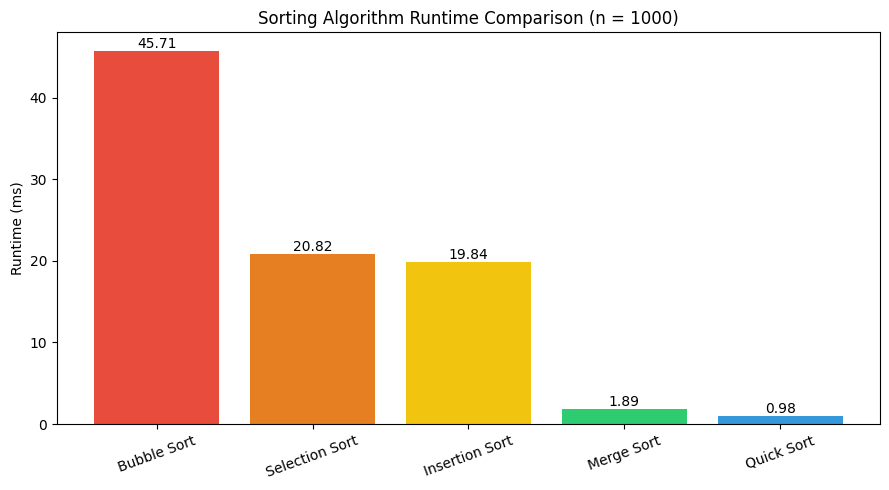

In [13]:
# --- Bar chart of runtimes ---
plt.figure(figsize=(9, 5))
names = list(results.keys())
times = list(results.values())
bars = plt.bar(names, times, color=['#e74c3c', '#e67e22', '#f1c40f', '#2ecc71', '#3498db'])
plt.ylabel("Runtime (ms)")
plt.title(f"Sorting Algorithm Runtime Comparison (n = {size})")
plt.xticks(rotation=20)
for bar, t in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{t:.2f}", ha='center', va='bottom')
plt.tight_layout()
plt.show()


## Summary Table

| Algorithm      | Best Case   | Average Case | Worst Case  | Space Complexity | Stable | In-Place |
|----------------|-------------|---------------|-------------|-------------------|--------|----------|
| Bubble Sort    | O(n)        | O(n^2)        | O(n^2)      | O(1)              | Yes    | Yes      |
| Selection Sort | O(n^2)      | O(n^2)        | O(n^2)      | O(1)              | No     | Yes      |
| Insertion Sort | O(n)        | O(n^2)        | O(n^2)      | O(1)              | Yes    | Yes      |
| Merge Sort     | O(n log n)  | O(n log n)    | O(n log n)  | O(n)              | Yes    | No       |
| Quick Sort     | O(n log n)  | O(n log n)    | O(n^2)      | O(log n) avg      | No     | Yes      |

**Notes:**
- For small or nearly-sorted lists, Insertion Sort and Bubble Sort can actually be faster than Merge/Quick sort due to low overhead.
- Merge Sort guarantees `O(n log n)` in every case but needs extra memory.
- Quick Sort is usually the fastest in practice (good cache locality, in-place), but its worst case is `O(n^2)` unless a randomized/median pivot is used.
